In [3]:
import torch
import deepwave
import matplotlib.pyplot as plt

NameError: name '_C' is not defined

In [2]:
v = 1500 * torch.ones(100, 100)
v[50:] = 2000
v.requires_grad_()

out = deepwave.scalar(
    v, grid_spacing=4, dt=0.004,
    source_amplitudes=deepwave.wavelets.ricker(25, 200, 0.004, 0.06).reshape(1, 1, -1),
    source_locations=torch.tensor([[[0, 0]]]),
    receiver_locations=torch.tensor([[[0, 99]]])
)

(out[-1]**2).sum().backward()

/home/staff/abdo/anaconda3/envs/newdeepwave/lib/python3.11/site-packages/numpy/core/getlimits.py:549: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  setattr(self, word, getattr(machar, word).flat[0])
/home/staff/abdo/anaconda3/envs/newdeepwave/lib/python3.11/site-packages/numpy/core/getlimits.py:89: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  return self._float_to_str(self.smallest_subnormal)


Text(0.5, 1.0, 'Gradient')

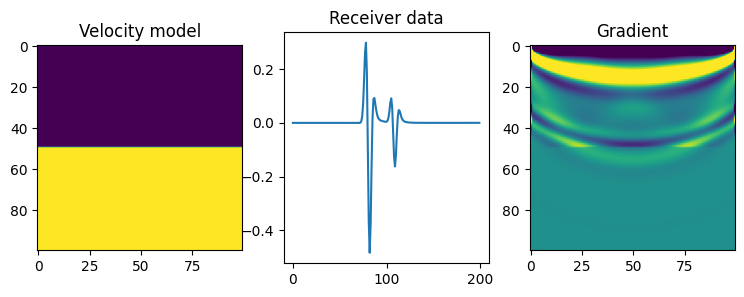

In [3]:
_, ax = plt.subplots(1, 3, figsize=(9, 3))
ax[0].imshow(v.detach())
ax[0].set_title("Velocity model")
ax[1].plot(out[-1].detach().flatten())
ax[1].set_title("Receiver data")
ax[2].imshow(v.grad.detach(), vmin=-1e-5, vmax=1e-5)
ax[2].set_title("Gradient")

In [4]:
out


(tensor([[[1.0961e-06, 3.9235e-06, 6.8807e-06,  ..., 1.6368e-05,
           9.4821e-06, 2.8031e-06],
          [3.9316e-06, 1.4022e-05, 2.4561e-05,  ..., 5.6975e-05,
           3.2923e-05, 9.7162e-06],
          [6.9037e-06, 2.4551e-05, 4.2894e-05,  ..., 1.0286e-04,
           5.9484e-05, 1.7547e-05],
          ...,
          [7.3541e-06, 2.6409e-05, 4.7586e-05,  ..., 9.5207e-05,
           5.2748e-05, 1.4976e-05],
          [4.1305e-06, 1.4864e-05, 2.6843e-05,  ..., 5.3497e-05,
           2.9654e-05, 8.4223e-06],
          [1.1559e-06, 4.1685e-06, 7.5476e-06,  ..., 1.5409e-05,
           8.5564e-06, 2.4305e-06]]], grad_fn=<ScalarForwardFuncBackward>),
 tensor([[[1.1060e-06, 3.9581e-06, 6.9430e-06,  ..., 1.6358e-05,
           9.4740e-06, 2.8006e-06],
          [3.9655e-06, 1.4140e-05, 2.4772e-05,  ..., 5.6930e-05,
           3.2886e-05, 9.7045e-06],
          [6.9621e-06, 2.4754e-05, 4.3255e-05,  ..., 1.0279e-04,
           5.9421e-05, 1.7526e-05],
          ...,
          [7.3906e-06